# Codebook kod korelasyonu ve şekil çeşitliliği

3B VQ-VAE ailesinin öğrendiği ayrık kod sözlüğünü (codebook) üç açıdan inceler:

1. **Kod gömme korelasyonu** — codebook vektörlerinin (K×D) birbirine benzerliği (K×K
   Pearson korelasyon / kosinüs). Yüksek benzerlik = kodlar birbirine yakın = düşük çeşitlilik.
2. **Efektif codebook kullanımı** — gerçek (temiz) hacimlerde fiilen seçilen kodların
   dağılımı, aktif kod sayısı ve perplexite. Sözlüğün ne kadarının gerçekten kullanıldığını gösterir.
3. **Decode edilmiş şekil (prototip) Dice matrisi** — her kod tek başına decode edilip
   ürettiği şekil çıkarılır; şekiller arası çift-çift Dice. Gömme korelasyonu lineerdir; şekil
   benzerliği decoder-sonrası olduğu için anatomik olarak daha anlamlı bir çeşitlilik ölçüsüdür.

Karşılaştırılan modeller: base VQ (ikili maske), WP-2 base (ikili maske), WP-3 SDF.
Ek olarak SDF modelinde en yakın rank'lara göre reconstruction görselleştirilir.


## 0) Kurulum — importlar, config, cihaz, modeller, veri

In [5]:
import sys
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
for p in (PROJECT_ROOT, PROJECT_ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from data import load_config
from train import resolve_device, set_seed
import evaluate_correlation_3d as ev3d
from evaluate_correlation_3d_vq import load_model
from evaluate_correlation_3d_sdf import load_sdf_model

EPS = 1e-6
print("proje kok:", PROJECT_ROOT)

proje kok: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality


In [6]:
config = load_config(str(PROJECT_ROOT / "configs" / "vae3d_vq.yaml"))
device = resolve_device(str(config["train"]["device"]))
CKPT_DIR = PROJECT_ROOT / "outputs" / "checkpoints"

base_model = load_model(CKPT_DIR / "vae3d_vqvae_best.pt", device); base_model.eval()
wp2_model  = load_model(CKPT_DIR / "vae3d_wp2_base_best.pt", device); wp2_model.eval()
sdf_model  = load_sdf_model(CKPT_DIR / "vae3d_wp3_sdf_best.pt", device); sdf_model.eval()

# (ad, model, sdf_mi) — sdf modelinde decode ciktisi ham SDF, kopru: sdf<0
MODELS = [
    ("base VQ (ikili)", base_model, False),
    ("WP-2 base (ikili)", wp2_model, False),
    ("WP-3 SDF", sdf_model, True),
]
for name, m, _ in MODELS:
    print(f"{name:18s} codebook = {tuple(m.quantizer.embedding.weight.shape)} (K x D)")
print("cihaz:", device)

base VQ (ikili)    codebook = (512, 64) (K x D)
WP-2 base (ikili)  codebook = (512, 64) (K x D)
WP-3 SDF           codebook = (512, 64) (K x D)
cihaz: cuda


In [7]:
# Temiz test hacimleri (kullanim analizi icin) + bir bozuk ornek (SDF rank gorseli icin)
SEED = 42
N_PER_MASK = 5
set_seed(SEED)
clean = ev3d.load_clean_volumes(config, "test", None, SEED)
degrader = ev3d.calibrate_degrader(config, clean, SEED)
masks, true_dice, is_clean = ev3d.build_eval_set(clean, degrader, N_PER_MASK, SEED)
block = 1 + N_PER_MASK
references = np.stack([masks[(i // block) * block] for i in range(len(masks))])
print(f"temiz hacim: {len(clean)} | toplam eval: {len(masks)} | bozuk: {int((~is_clean).sum())}")

temiz hacim: 47 | toplam eval: 282 | bozuk: 235


## 1) Yardımcı fonksiyonlar

In [8]:
def to_x(mask_np):
    return torch.from_numpy(mask_np.astype(np.float32))[None, None].to(device)


@torch.no_grad()
def grid_dims(model):
    """Kodlayicinin uzamsal izgara boyutu (b,D,d,h,w) — tum modellerde 4x4x4=64."""
    z_e, _ = model._encode_features(to_x(clean[0]))
    return z_e.shape


def corr_matrix(W):
    """K kod vektoru (satir) arasi Pearson korelasyon: (K,K)."""
    return np.corrcoef(W)


def cosine_matrix(W):
    Wn = W / (np.linalg.norm(W, axis=1, keepdims=True) + EPS)
    return Wn @ Wn.T


def offdiag_mean_abs(M):
    """Kosegen disi mutlak ortalama — 1'e yakin = kodlar birbirine cok benzer."""
    K = M.shape[0]
    mask = ~np.eye(K, dtype=bool)
    return float(np.abs(M[mask]).mean())


@torch.no_grad()
def usage_counts(model, vols):
    """Verilen hacimlerde her pozisyon icin en yakin kodu say: (K,) histogram."""
    W = model.quantizer.embedding.weight
    K = W.shape[0]
    counts = np.zeros(K, dtype=np.int64)
    for v in vols:
        z_e, _ = model._encode_features(to_x(v))
        b, D, d, h, w = z_e.shape
        z = z_e.permute(0, 2, 3, 4, 1).contiguous().view(-1, D)
        dist = z.pow(2).sum(1, keepdim=True) - 2.0 * z @ W.t() + W.pow(2).sum(1)
        idx = dist.argmin(-1).cpu().numpy()
        np.add.at(counts, idx, 1)
    return counts


def usage_stats(counts):
    total = counts.sum()
    p = counts[counts > 0] / total
    perplexity = float(np.exp(-(p * np.log(p)).sum()))
    active = int((counts > 0).sum())
    return active, perplexity


@torch.no_grad()
def decode_prototypes(model, is_sdf, dims, batch=32):
    """Her kodu TUM pozisyonlara doldurup decode et -> (K,64,64,64) ikili prototip sekil."""
    b, D, d, h, w = dims
    P = d * h * w
    K = model.quantizer.embedding.weight.shape[0]
    shapes = np.empty((K, 64, 64, 64), dtype=bool)
    for s in range(0, K, batch):
        ks = torch.arange(s, min(s + batch, K), device=device)
        nb = ks.shape[0]
        idx = ks.view(nb, 1).expand(nb, P)
        z_q = model.quantizer.embedding(idx).view(nb, d, h, w, D).permute(0, 4, 1, 2, 3).contiguous()
        out = model._decode_features(z_q, feats=[])
        binshape = (out[:, 0] < 0) if is_sdf else (torch.sigmoid(out[:, 0]) > 0.5)
        shapes[s:s + nb] = binshape.cpu().numpy()
    return shapes


def dice_matrix(shapes):
    """(K,64,64,64) ikili -> (K,K) cift-cift Dice (GPU matmul)."""
    A = torch.from_numpy(shapes.reshape(shapes.shape[0], -1).astype(np.float32)).to(device)
    inter = A @ A.t()
    s = A.sum(1)
    D = 2.0 * inter / (s[:, None] + s[None, :] + EPS)
    return D.cpu().numpy()


@torch.no_grad()
def candidate_by_ranks(model, x, ranks, is_sdf):
    """Verilen rank'lar icin her adayi AYRI decode et -> {rank: (sekil np, ort_uzaklik)}."""
    z_e, _ = model._encode_features(x)
    b, D, d, h, w = z_e.shape
    z = z_e.permute(0, 2, 3, 4, 1).contiguous().view(b, -1, D)
    W = model.quantizer.embedding.weight
    dist = (z.pow(2).sum(-1, keepdim=True) - 2.0 * z @ W.t() + W.pow(2).sum(1)).clamp_min(0.0)
    order = torch.argsort(dist, dim=-1)
    out = {}
    for r in ranks:
        idx = order[..., r]
        d_r = torch.gather(dist, -1, idx.unsqueeze(-1)).squeeze(-1).mean().item()
        z_q = model.quantizer.embedding(idx).view(b, d, h, w, D).permute(0, 4, 1, 2, 3).contiguous()
        o = model._decode_features(z_q, feats=[])
        shape = (o[0, 0] < 0).cpu().numpy() if is_sdf else (torch.sigmoid(o[0, 0]) > 0.5).cpu().numpy()
        out[r] = (shape, d_r)
    return out


def dice(a, b):
    a = a > 0.5; b = b > 0.5
    inter = np.logical_and(a, b).sum()
    return float(2.0 * inter / (a.sum() + b.sum() + EPS))

## 2) Kod gömme (embedding) korelasyon matrisi

Her modelin K×D codebook'undaki kod vektörleri arasında Pearson korelasyonu. Köşegen dışı
mutlak ortalama yüksekse (1'e yakın), kodlar birbirinin benzeri demektir — sözlük çeşitliliği düşüktür.


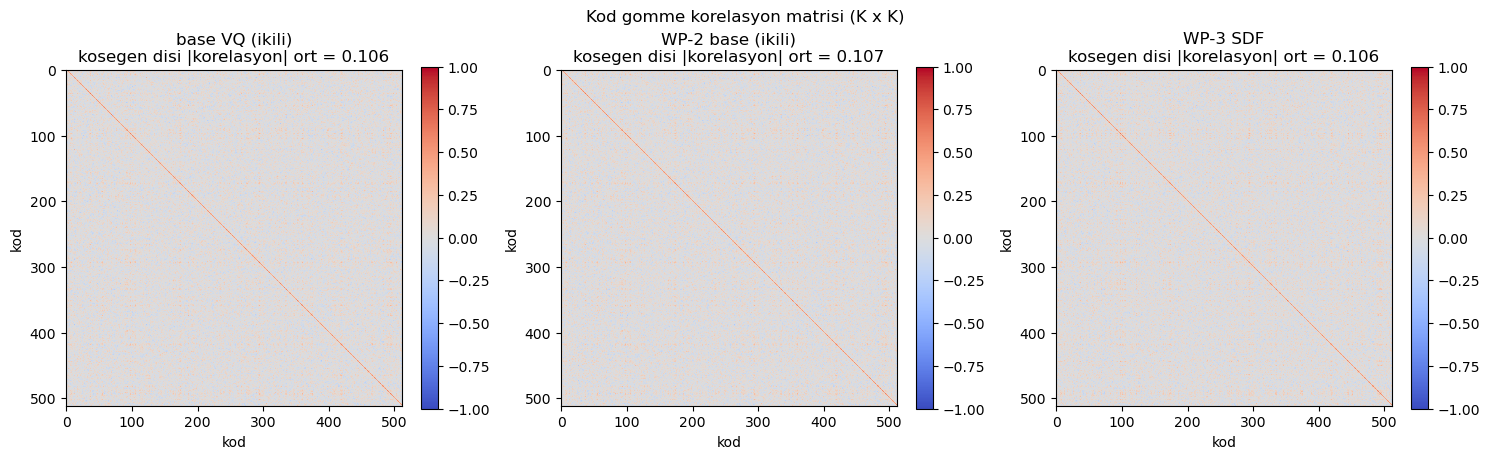

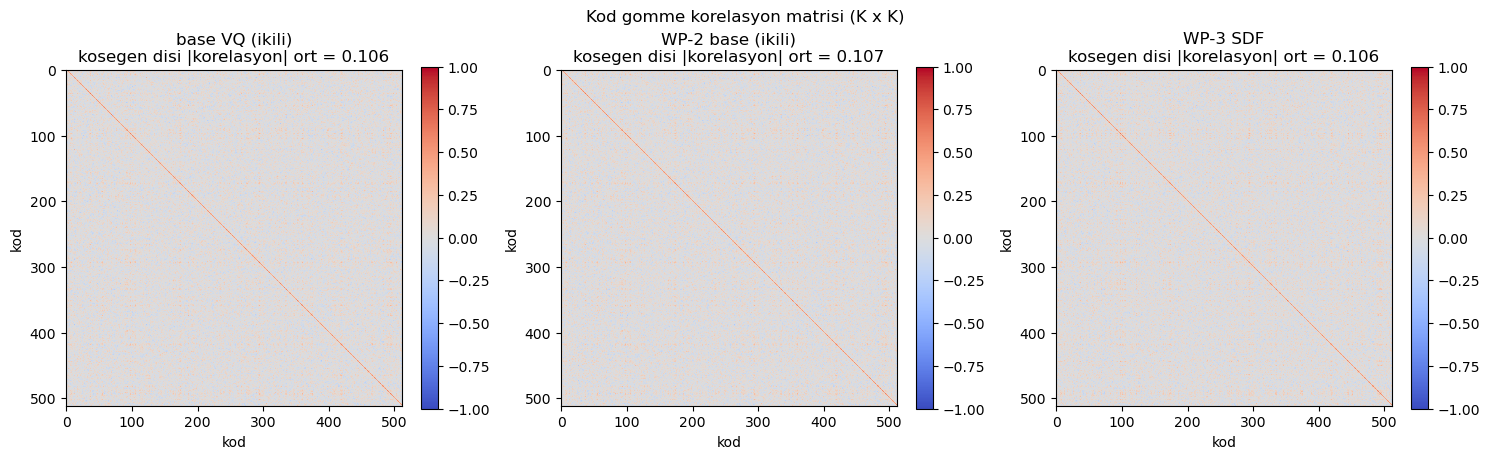

Kosegen disi |korelasyon| ortalamasi (yuksek = daha az cesitlilik):
  base VQ (ikili)   : 0.1063
  WP-2 base (ikili) : 0.1066
  WP-3 SDF          : 0.1062


In [9]:
corr_stats = {}
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 4.5))
for ax, (name, model, _) in zip(axes, MODELS):
    W = model.quantizer.embedding.weight.detach().cpu().numpy()
    C = corr_matrix(W)
    corr_stats[name] = offdiag_mean_abs(C)
    im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(f"{name}\nkosegen disi |korelasyon| ort = {corr_stats[name]:.3f}")
    ax.set_xlabel("kod"); ax.set_ylabel("kod")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Kod gomme korelasyon matrisi (K x K)")
fig.tight_layout(); plt.show()

print("Kosegen disi |korelasyon| ortalamasi (yuksek = daha az cesitlilik):")
for name, v in corr_stats.items():
    print(f"  {name:18s}: {v:.4f}")

## 3) Efektif codebook kullanımı

Temiz test hacimleri modele verilip her uzamsal pozisyon en yakın koda atanır; seçilen kodların
histogramı çıkarılır. **Aktif kod** = en az bir kez seçilen kod sayısı. **Perplexite** = kullanım
dağılımının efektif genişliği (K'ya yakınsa dengeli/çeşitli, çok düşükse birkaç koda yığılmış).


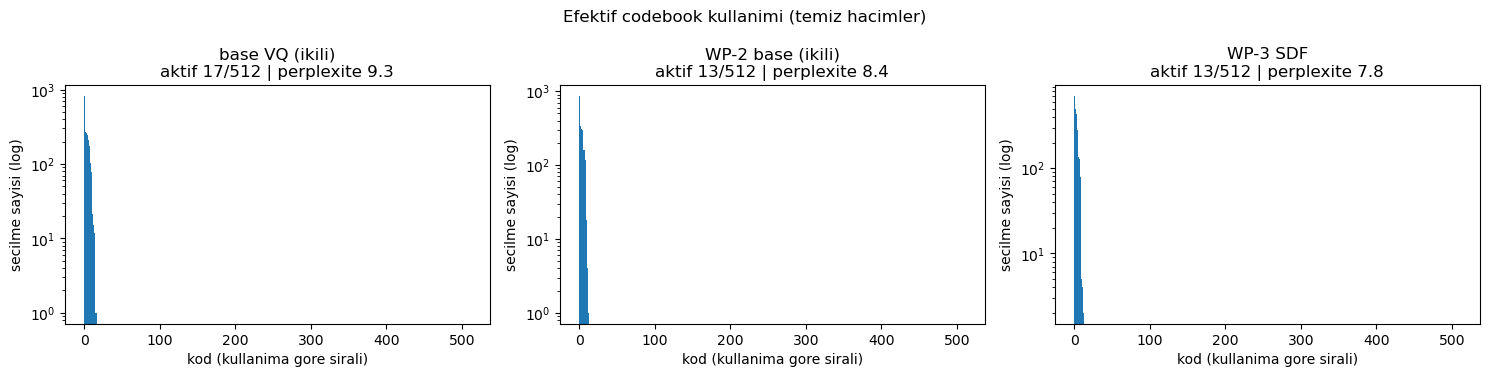

aktif kod / toplam | perplexite | toplam atama:
  base VQ (ikili)   :  17/512 | ppl    9.3 | 3008 atama
  WP-2 base (ikili) :  13/512 | ppl    8.4 | 3008 atama
  WP-3 SDF          :  13/512 | ppl    7.8 | 3008 atama


In [10]:
use_stats = {}
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 3.8))
for ax, (name, model, _) in zip(axes, MODELS):
    counts = usage_counts(model, clean)
    active, ppl = usage_stats(counts)
    use_stats[name] = (active, ppl, int(counts.sum()))
    K = counts.shape[0]
    ax.bar(np.arange(K), np.sort(counts)[::-1], width=1.0)
    ax.set_yscale("log")
    ax.set_title(f"{name}\naktif {active}/{K} | perplexite {ppl:.1f}")
    ax.set_xlabel("kod (kullanima gore sirali)"); ax.set_ylabel("secilme sayisi (log)")
fig.suptitle("Efektif codebook kullanimi (temiz hacimler)")
fig.tight_layout(); plt.show()

print("aktif kod / toplam | perplexite | toplam atama:")
for name, (a, ppl, tot) in use_stats.items():
    print(f"  {name:18s}: {a:3d}/512 | ppl {ppl:6.1f} | {tot} atama")

## 4) Decode edilmiş şekil (prototip) Dice matrisi

Her kod tek başına (tüm pozisyonlar aynı kodla doldurularak) decode edilir ve ürettiği ikili
prototip şekil çıkarılır. Şekiller arası çift-çift Dice, kodların **anatomik** olarak ne kadar
farklı şekiller ürettiğini gösterir. Köşegen dışı Dice ortalaması yüksekse kodlar benzer şekiller
üretiyor (çeşitlilik düşük). SDF modelinde prototip, `sdf<0` köprüsüyle ikili maskeye çevrilir.

Not: Tüm pozisyonları tek kodla doldurmak homojen bir latent üretir; bu kaba bir prototip ölçüsüdür
ve şeklin uzamsal düzeninden gelen çeşitliliği yansıtmaz. Bir örnek içindeki gerçek rank-bazlı
çeşitlilik bölüm 5'te görülür.

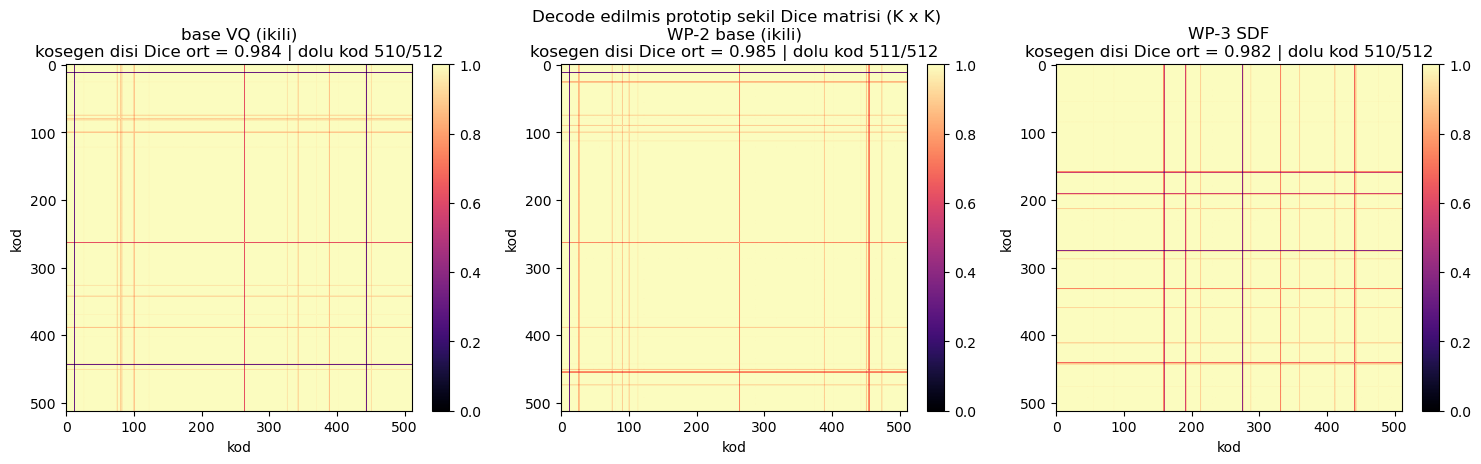

Kosegen disi prototip Dice ortalamasi (yuksek = sekiller birbirine benzer):
  base VQ (ikili)   : 0.9841
  WP-2 base (ikili) : 0.9855
  WP-3 SDF          : 0.9816


In [11]:
proto_dice = {}
proto_cache = {}
fig, axes = plt.subplots(1, len(MODELS), figsize=(15, 4.5))
for ax, (name, model, is_sdf) in zip(axes, MODELS):
    dims = grid_dims(model)
    shapes = decode_prototypes(model, is_sdf, dims)
    proto_cache[name] = shapes
    Dm = dice_matrix(shapes)
    K = Dm.shape[0]
    mask = ~np.eye(K, dtype=bool)
    proto_dice[name] = float(Dm[mask].mean())
    nonempty = int((shapes.reshape(K, -1).sum(1) > 0).sum())
    im = ax.imshow(Dm, cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{name}\nkosegen disi Dice ort = {proto_dice[name]:.3f} | dolu kod {nonempty}/{K}")
    ax.set_xlabel("kod"); ax.set_ylabel("kod")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Decode edilmis prototip sekil Dice matrisi (K x K)")
fig.tight_layout(); plt.show()

print("Kosegen disi prototip Dice ortalamasi (yuksek = sekiller birbirine benzer):")
for name, v in proto_dice.items():
    print(f"  {name:18s}: {v:.4f}")

## 5) SDF modeli — en yakın rank'lara göre reconstruction

Bozuk bir hacim SDF modeline verilir; her uzamsal pozisyonda kodlar uzaklığa göre sıralanır.
Seçilen rank'lardaki kodlar ayrı ayrı decode edilip `sdf<0` köprüsüyle ikili maskeye çevrilir.
Rank 0 en yakın (en anlamlı) reconstruction; uzak rank'lar kodun temsil ettiği alternatif şekilleri
gösterir. Başlıkta ortalama uzaklık ve temiz referansa Dice yer alır.


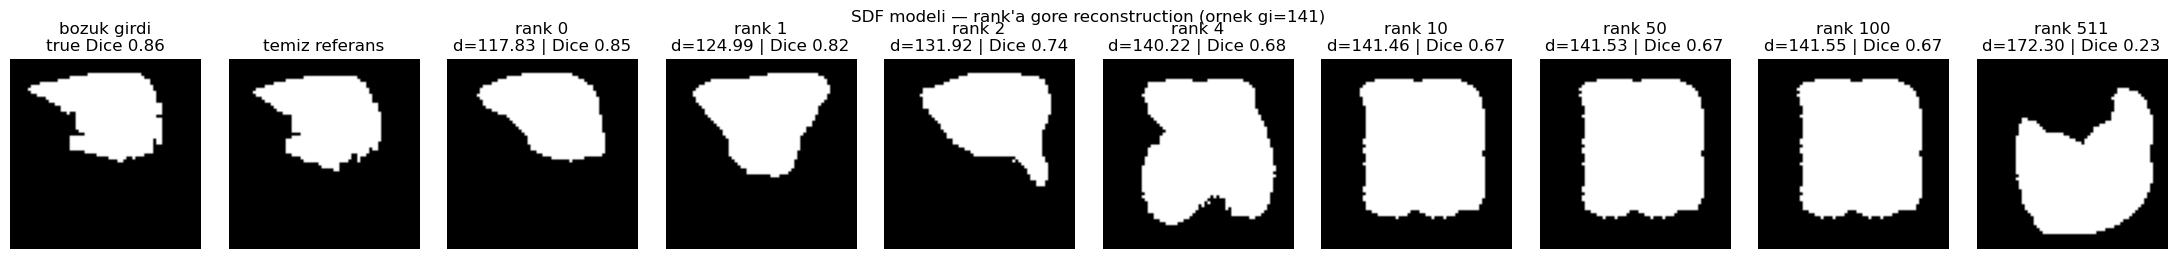

In [12]:
# bir bozuk ornek sec
deg_idx = np.where(~is_clean)[0]
gi = int(deg_idx[len(deg_idx) // 2])
inp = masks[gi]; ref = references[gi]
zc = 32  # orta eksenel kesit

RANKS = [0, 1, 2, 4, 10, 50, 100, 511]
cands = candidate_by_ranks(sdf_model, to_x(inp), RANKS, is_sdf=True)

ncol = 2 + len(RANKS)
fig, axes = plt.subplots(1, ncol, figsize=(2.2 * ncol, 2.6))
axes[0].imshow(inp[zc], cmap="gray"); axes[0].set_title(f"bozuk girdi\ntrue Dice {true_dice[gi]:.2f}"); axes[0].axis("off")
axes[1].imshow(ref[zc], cmap="gray"); axes[1].set_title("temiz referans"); axes[1].axis("off")
for ax, r in zip(axes[2:], RANKS):
    shape, d_r = cands[r]
    ax.imshow(shape[zc], cmap="gray")
    ax.set_title(f"rank {r}\nd={d_r:.2f} | Dice {dice(shape, ref):.2f}")
    ax.axis("off")
fig.suptitle(f"SDF modeli — rank'a gore reconstruction (ornek gi={gi})")
fig.tight_layout(); plt.show()

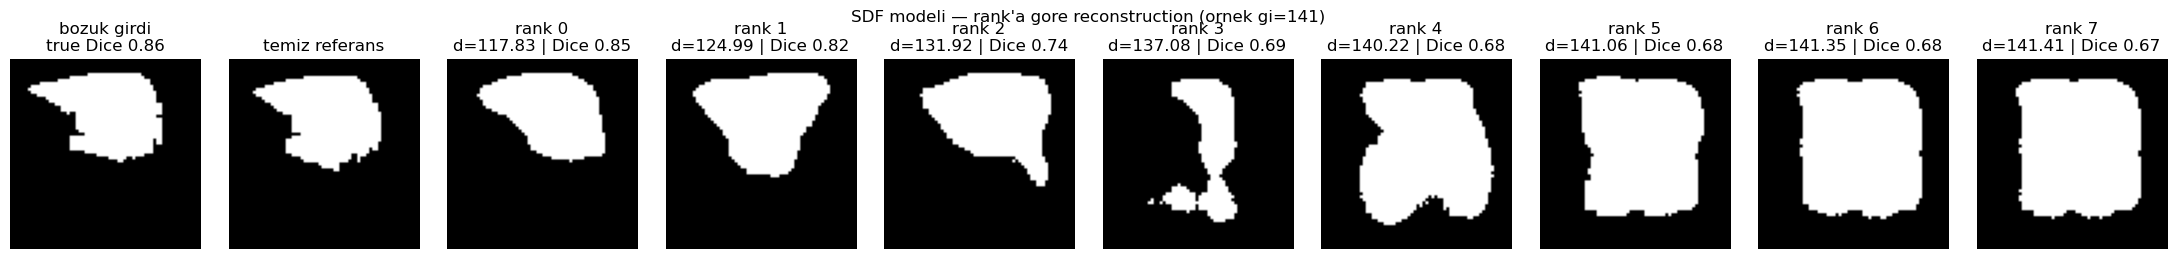

In [13]:
# bir bozuk ornek sec
deg_idx = np.where(~is_clean)[0]
gi = int(deg_idx[len(deg_idx) // 2])
inp = masks[gi]; ref = references[gi]
zc = 32  # orta eksenel kesit

RANKS = [0, 1, 2, 3,4,5,6,7]
cands = candidate_by_ranks(sdf_model, to_x(inp), RANKS, is_sdf=True)

ncol = 2 + len(RANKS)
fig, axes = plt.subplots(1, ncol, figsize=(2.2 * ncol, 2.6))
axes[0].imshow(inp[zc], cmap="gray"); axes[0].set_title(f"bozuk girdi\ntrue Dice {true_dice[gi]:.2f}"); axes[0].axis("off")
axes[1].imshow(ref[zc], cmap="gray"); axes[1].set_title("temiz referans"); axes[1].axis("off")
for ax, r in zip(axes[2:], RANKS):
    shape, d_r = cands[r]
    ax.imshow(shape[zc], cmap="gray")
    ax.set_title(f"rank {r}\nd={d_r:.2f} | Dice {dice(shape, ref):.2f}")
    ax.axis("off")
fig.suptitle(f"SDF modeli — rank'a gore reconstruction (ornek gi={gi})")
fig.tight_layout(); plt.show()

## 6) Özet

Üç ölçünün birlikte okunması:

- **Kod gömme korelasyonu** (bölüm 2) — köşegen dışı mutlak ortalama yüksekse codebook vektörleri
  birbirine yakın.
- **Efektif kullanım** (bölüm 3) — aktif kod sayısı ve perplexite düşükse sözlüğün küçük bir kısmı
  gerçekten kullanılıyor; kalan kodlar atıl.
- **Prototip Dice** (bölüm 4) — köşegen dışı Dice yüksekse, farklı kodlar benzer şekiller üretiyor;
  bu, gömme korelasyonundan bağımsız olarak decoder çıktısındaki şekil çeşitliliğini ölçer.

Bu üç ölçüt birlikte, "kodların bir yerden sonra benzer şekilleri kodlaması" gözlemini niceliksel
olarak modeller arası (base VQ / WP-2 base / WP-3 SDF) karşılaştırır.
